# DL_04 — Coordinate prediction (single-task DL)

**Purpose.** Regress `LONGITUDE`/`LATITUDE`. Targets are centred on the internal-train mean and divided by 10 dataset units; the loss is Huber (delta = 1, i.e. 10 units). Errors are reported in dataset coordinate units (ML_04 labels them EPSG:3857 metres; the CRS is not independently confirmed).

**Model.** The shared-trunk MLP from `src/signal2space_dl/model.py` with only the **coordinate** head
enabled (`experiment="coordinate_only"`). It is a single-task ablation: comparing it with the multitask model in
DL_05 shows whether sharing a trunk across tasks helps or hurts this target.

**Selection.** Fixed a-priori hyperparameters (`TrainConfig`), early stopping on the
internal-validation loss. The held-out partition is scored only after the checkpoint is frozen; the
evaluation step re-checks the checkpoint SHA-256 recorded at training time.

**Outputs.** `models/dl_04_coordinate_model.pt|json`, `data/tables/dl_04_coordinate_*`, `data/figures/dl_04_coordinate_*`.

In [1]:
import sys
from pathlib import Path

# Locate the repository root whether Jupyter starts in the root or in "Deep Learning Pipeline/".
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "signal2space_dl").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json, platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from signal2space_dl import config as C, data as D, evaluate as E, plots as P
from signal2space_dl.cli import run_compare, run_evaluate, run_train

paths = C.Paths(ROOT).ensure()
cfg = C.TrainConfig()
pd.set_option("display.width", 160, "display.max_columns", 30)
print(f"Repository: {ROOT}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | pandas {pd.__version__} | NumPy {np.__version__}")

Repository: /home/user/Signal2Space
Python 3.13.18 | torch 2.15.0+cu132 | pandas 3.0.6 | NumPy 2.5.4


In [2]:
data = D.prepare(paths, coord_scale=cfg.coord_scale, save=False)
print({s: len(f) for s, f in data.frames.items()})

{'internal_train': 16085, 'internal_validation': 3852, 'heldout_validation': 1111}


## 1. Train (or reuse the frozen checkpoint)

In [3]:
CHECKPOINT = paths.models / "dl_04_coordinate_model.pt"
RETRAIN = False   # set True to retrain from scratch; the default reuses the committed checkpoint
if RETRAIN or not CHECKPOINT.exists():
    run_train(data, paths, cfg, ["coordinate_only"])
meta = json.loads((paths.models / "dl_04_coordinate_model.json").read_text())
print(json.dumps({k: meta[k] for k in ["tasks", "selected_epoch", "epochs_run", "best_internal_validation_loss",
                                       "n_parameters", "training_seconds", "device", "torch_version"]}, indent=1))

{
 "tasks": [
  "coordinate"
 ],
 "selected_epoch": 100,
 "epochs_run": 115,
 "best_internal_validation_loss": 0.24137571755785064,
 "n_parameters": 699010,
 "training_seconds": 96.4,
 "device": "cpu",
 "torch_version": "2.15.0+cu132"
}


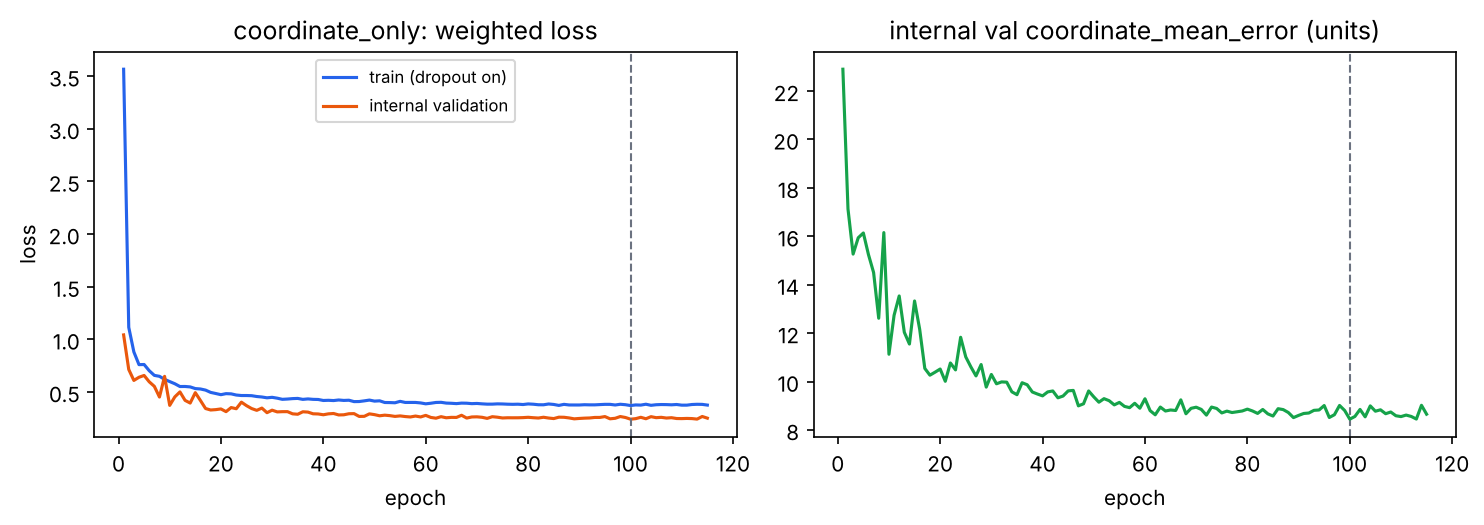

In [4]:
history = pd.read_csv(paths.tables / "dl_04_coordinate_training_history.csv")
P.training_curves(history, paths, "dl_04_coordinate", "coordinate_only")
display(Image(paths.figures / "dl_04_coordinate_training_curves.png"))

## 2. Evaluate the frozen model (internal validation, then held-out)

In [5]:
preds, rows = run_evaluate(data, paths, ["coordinate_only"])
metrics = pd.DataFrame(rows).drop(columns=["checkpoint_sha256"])
display(metrics.round(4))

,model,experiment,split,task,n_rows,selected_epoch,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p75_euclidean_error,p90_euclidean_error,rmse_euclidean,coordinate_unit
0,DL coordinate_only,coordinate_only,internal_validation,coordinate,3852,100,6.0487,4.7078,8.4456,6.7890,10.6922,15.9293,11.4631,dataset coordinate units (EPSG:3857 metres per...
1,DL coordinate_only,coordinate_only,heldout_validation,coordinate,1111,100,7.2448,6.1074,10.5066,8.1348,14.1295,21.3471,13.4570,dataset coordinate units (EPSG:3857 metres per...


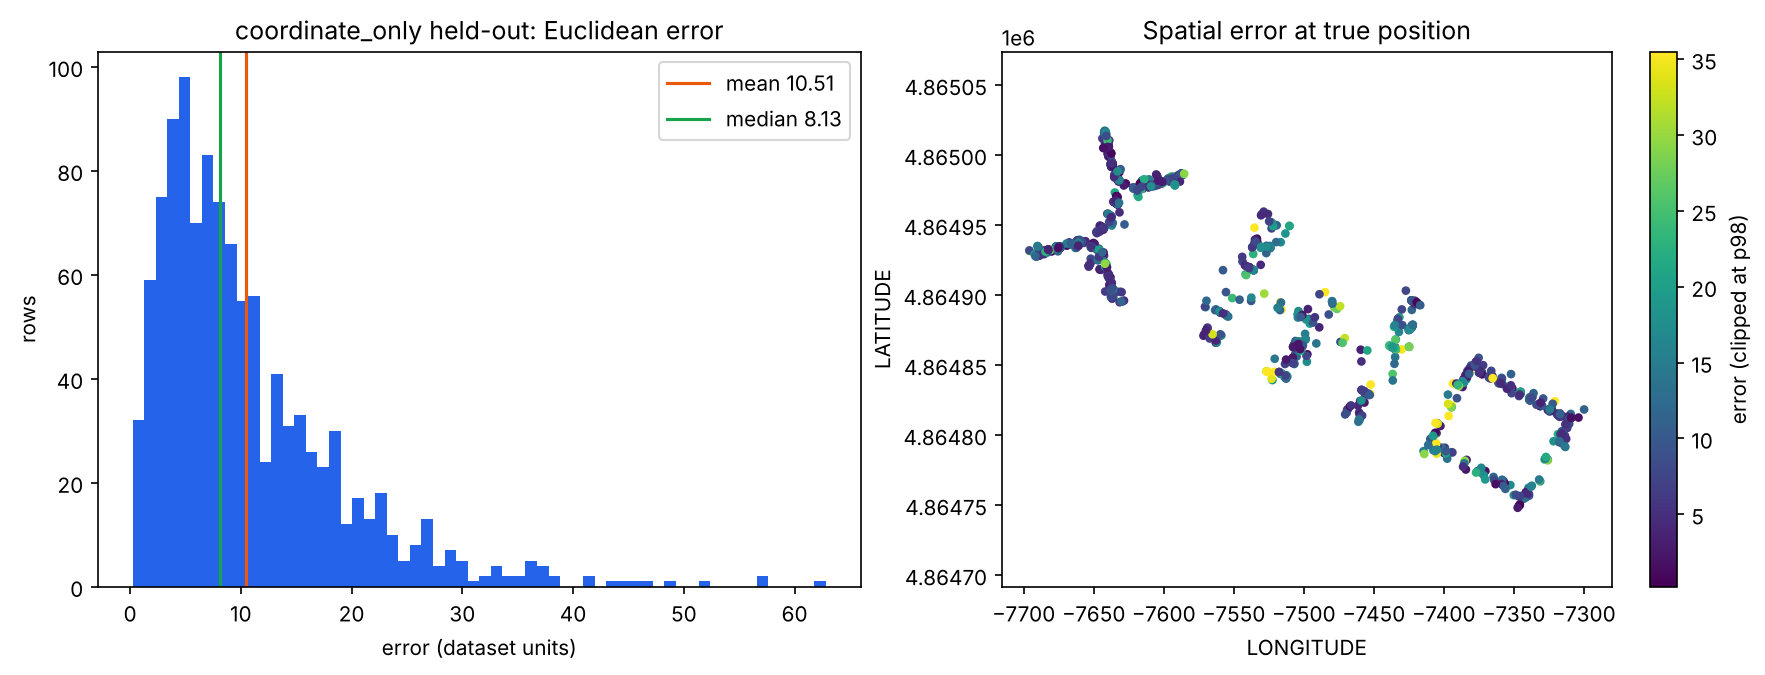

In [6]:
display(Image(paths.figures / "dl_04_coordinate_errors.png"))

## 3. Same-partition comparison with the AML baseline

In [7]:
aml = pd.DataFrame(E.aml_metric_rows(paths))
cmp = pd.concat([aml[aml.task == "coordinate"], metrics[metrics.task == "coordinate"]], ignore_index=True)
cols = [c for c in ["model", "split", "accuracy", "macro_f1", "balanced_accuracy", "mae_longitude", "mae_latitude",
                    "mean_euclidean_error", "median_euclidean_error", "p90_euclidean_error"] if c in cmp]
display(cmp[cols].round(4))

,model,split,accuracy,macro_f1,balanced_accuracy,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p90_euclidean_error
0,AML Random Forest,internal_validation,NaN,NaN,NaN,5.9142,5.0607,8.5786,6.3067,17.3765
1,AML Random Forest,heldout_validation,NaN,NaN,NaN,8.0966,6.8064,11.5836,7.4884,24.3892
2,DL coordinate_only,internal_validation,NaN,NaN,NaN,6.0487,4.7078,8.4456,6.7890,15.9293
3,DL coordinate_only,heldout_validation,NaN,NaN,NaN,7.2448,6.1074,10.5066,8.1348,21.3471


## Findings

- The frozen coordinate-only model, selected at epoch 100 of 115, gets a held-out MAE of **7.24** (longitude) and **6.11** (latitude). Its mean Euclidean error is **10.51** and its median is **8.13** dataset units.
- AML gets 8.10, 6.81, 11.58 and 7.49 on the same rows. The DL mean error is lower by 1.08 units (paired bootstrap 95% CI [-1.78, -0.37]).
- The DL model also has a lower p90 (21.35 vs 24.39) and RMSE (13.46 vs 17.67). AML still has the lower median (7.49 vs 8.13).
- Read this as: DL reduces large errors, while the Random Forest is more precise on typical rows.
- Units: the values follow the ML_04 EPSG:3857 label. That label is unconfirmed, and Web-Mercator distances overstate ground distance at this latitude.